<>:67: SyntaxWarning: invalid escape sequence '\D'
<>:68: SyntaxWarning: invalid escape sequence '\D'
<>:67: SyntaxWarning: invalid escape sequence '\D'
<>:68: SyntaxWarning: invalid escape sequence '\D'
C:\Users\salma\AppData\Local\Temp\ipykernel_19300\1658157002.py:67: SyntaxWarning: invalid escape sequence '\D'
  b1 = ax2.bar(x, t_repair, width=0.4, color='#8172B3', label='Repair Latency ($\Delta T_r$)')
C:\Users\salma\AppData\Local\Temp\ipykernel_19300\1658157002.py:68: SyntaxWarning: invalid escape sequence '\D'
  l1 = ax2_bar.plot(x, t_total, color='#CCB974', marker='o', linewidth=2.5, markersize=8, label='Total Stream Latency ($\Delta T$)')


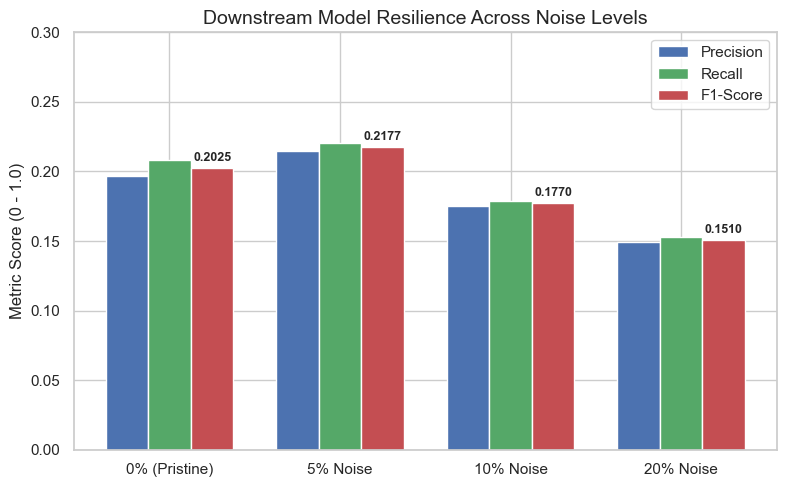

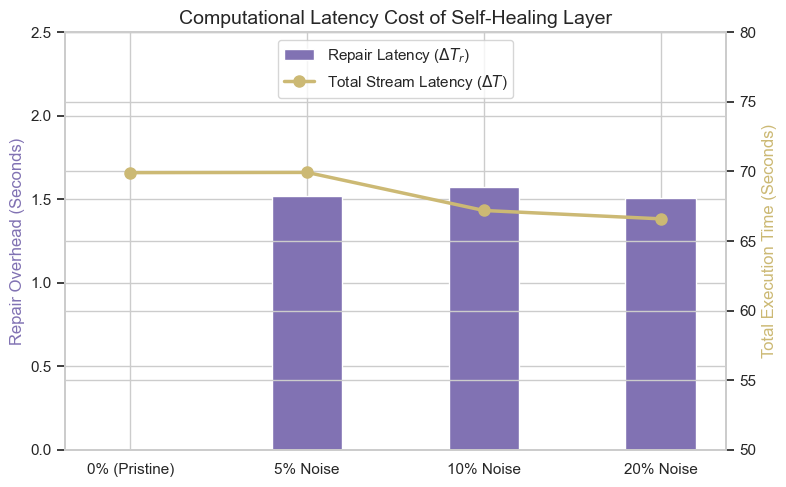

✅ Saved 'fig1_model_resilience.png' and 'fig2_latency_overhead.png' at 300 DPI!


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set publication style
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.titlesize': 16
})

# Experimental Data
noise_levels = ['0% (Pristine)', '5% Noise', '10% Noise', '20% Noise']
f1_scores = [0.2025, 0.2177, 0.1770, 0.1510]
precision = [0.1968, 0.2150, 0.1749, 0.1492]
recall = [0.2085, 0.2204, 0.1791, 0.1529]

t_total = [69.9178, 69.9336, 67.1979, 66.5979]
t_repair = [0.0000, 1.5183, 1.5720, 1.5060]
t_valid = [0.8015, 0.1187, 0.1077, 0.1102]

# ----------------------------------------------------
# FIGURE 1: Model Performance Degradation & Resilience
# ----------------------------------------------------
fig, ax1 = plt.subplots(figsize=(8, 5))

x = np.arange(len(noise_levels))
width = 0.25

rects1 = ax1.bar(x - width, precision, width, label='Precision', color='#4C72B0')
rects2 = ax1.bar(x, recall, width, label='Recall', color='#55A868')
rects3 = ax1.bar(x + width, f1_scores, width, label='F1-Score', color='#C44E52')

ax1.set_ylabel('Metric Score (0 - 1.0)')
ax1.set_title('Downstream Model Resilience Across Noise Levels')
ax1.set_xticks(x)
ax1.set_xticklabels(noise_levels)
ax1.set_ylim(0, 0.30)
ax1.legend(loc='upper right', frameon=True)

# Annotate F1 values on top of bars
for rect in rects3:
    height = rect.get_height()
    ax1.annotate(f'{height:.4f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('fig1_model_resilience.png', dpi=300)
plt.show()

# ----------------------------------------------------
# FIGURE 2: Overhead Latency Analysis (Validation vs Repair vs Total)
# ----------------------------------------------------
fig, ax2 = plt.subplots(figsize=(8, 5))

# Plot total stream time as line, repair overhead as bar
ax2_bar = ax2.twinx()

b1 = ax2.bar(x, t_repair, width=0.4, color='#8172B3', label='Repair Latency ($\Delta T_r$)')
l1 = ax2_bar.plot(x, t_total, color='#CCB974', marker='o', linewidth=2.5, markersize=8, label='Total Stream Latency ($\Delta T$)')

ax2.set_ylabel('Repair Overhead (Seconds)', color='#8172B3')
ax2_bar.set_ylabel('Total Execution Time (Seconds)', color='#CCB974')
ax2.set_xticks(x)
ax2.set_xticklabels(noise_levels)
ax2.set_ylim(0, 2.5)
ax2_bar.set_ylim(50, 80)

ax2.set_title('Computational Latency Cost of Self-Healing Layer')

# Combine legends
lines_1, labels_1 = ax2.get_legend_handles_labels()
lines_2, labels_2 = ax2_bar.get_legend_handles_labels()
ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center', frameon=True)

plt.tight_layout()
plt.savefig('fig2_latency_overhead.png', dpi=300)
plt.show()

print("✅ Saved 'fig1_model_resilience.png' and 'fig2_latency_overhead.png' at 300 DPI!")